# Распознавание овощей — Часть 1 (разбор данных) + Трек B (классические модели)

**Как запускать:** Colab → Runtime → Change runtime type → **T4 GPU** → Runtime → Run all.
GPU нужен только чтобы быстро посчитать эмбеддинги (~2–3 мин). Всё остальное — sklearn, секунды.

В конце ноутбук сам соберёт папку `repo/` (predict.py, веса, requirements.txt, графики) и скачает `repo.zip`.

In [1]:
!pip -q install kagglehub imagehash

In [2]:
import os, io, re, json, hashlib, random, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps
import imagehash
from skimage.feature import hog
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import torch, torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, log_loss)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
CLASSES = ['Capsicum', 'Carrot', 'Cucumber', 'Potato', 'Raddish', 'Squash']
EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
REPO = Path('/content/repo'); (REPO / 'weights').mkdir(parents=True, exist_ok=True)
FIG = REPO / 'figures'; FIG.mkdir(exist_ok=True)
RESULTS = {}
print('device:', DEVICE)

device: cuda


## 0. Скачиваем датасет и смотрим структуру папок

In [3]:
import kagglehub
DATA = Path(kagglehub.dataset_download('preethi866/vegetable-dataset'))
print(DATA)
for root, dirs, files in os.walk(DATA):
    depth = len(Path(root).relative_to(DATA).parts)
    if depth <= 3:
        print('  ' * depth + Path(root).name + f'/  ({len(files)} files)')

Using Colab cache for faster access to the 'vegetable-dataset' dataset.
/kaggle/input/vegetable-dataset
vegetable-dataset/  (0 files)
  Dataset/  (0 files)
    Dataset/  (0 files)
      Capsicum/  (615 files)
      Raddish/  (286 files)
      Carrot/  (905 files)
      Squash/  (1343 files)
      Cucumber/  (308 files)
      Potato/  (422 files)
  final_dataset/  (0 files)
    final_dataset/  (0 files)
      val/  (0 files)
      test/  (0 files)
      train/  (0 files)


In [4]:
def norm(name):
    # 'Raddish' / 'Radish' -> same key
    return name.lower().replace('dd', 'd')

def class_dirs(root):
    # Return {class: folder} if root contains all 6 class folders, else None
    sub = {norm(d.name): d for d in Path(root).iterdir() if d.is_dir()}
    found = {c: sub.get(norm(c)) for c in CLASSES}
    return found if all(found.values()) else None

roots = [Path(r) for r, _, _ in os.walk(DATA) if class_dirs(r)]
rel = lambda r: str(r.relative_to(DATA)).lower()
for r in roots: print(r.relative_to(DATA))

# If auto-detection picks a wrong folder, set these 3 paths by hand
ALL_ROOT   = next(r for r in roots if 'final_dataset' not in rel(r))
TRAIN_ROOT = next(r for r in roots if 'final_dataset' in rel(r) and 'train' in rel(r))
TEST_ROOT  = next(r for r in roots if 'final_dataset' in rel(r) and 'test' in rel(r))
print('ALL  :', ALL_ROOT); print('TRAIN:', TRAIN_ROOT); print('TEST :', TEST_ROOT)

Dataset/Dataset
final_dataset/final_dataset/val
final_dataset/final_dataset/test
final_dataset/final_dataset/train
ALL  : /kaggle/input/vegetable-dataset/Dataset/Dataset
TRAIN: /kaggle/input/vegetable-dataset/final_dataset/final_dataset/train
TEST : /kaggle/input/vegetable-dataset/final_dataset/final_dataset/test


In [5]:
def list_images(root):
    rows = []
    for c, d in class_dirs(root).items():
        for p in sorted(d.rglob('*')):
            if p.is_file():
                rows.append({'path': str(p), 'label': c, 'name': p.name, 'ext': p.suffix.lower()})
    t = pd.DataFrame(rows)
    print(root.name, '| all file types:', t.ext.value_counts().to_dict())
    return t[t.ext.isin(EXTS)].reset_index(drop=True)

df    = list_images(ALL_ROOT)
tr_df = list_images(TRAIN_ROOT)
te_df = list_images(TEST_ROOT)
print(len(df), 'images in Dataset/ |', len(tr_df), 'train +', len(te_df), 'test in final_dataset/')

Dataset | all file types: {'.jpg': 3879}
train | all file types: {'.jpg': 3779}
test | all file types: {'.jpg': 799}
3879 images in Dataset/ | 3779 train + 799 test in final_dataset/


# Часть 1. Разбор данных

### 1.1 Читаем каждое фото один раз: размер, формат, хеши и простые признаки

- **md5** — хеш байтов файла. Одинаковый md5 = файл скопирован 1-в-1.
- **perceptual hash (pHash)** — «отпечаток» того, *как картинка выглядит*. Если фото пережали,
  чуть изменили яркость или размер — pHash почти не меняется. Расстояние между хешами
  (сколько из 64 битов отличаются) = насколько фото похожи.
- **простые признаки** для Трека B: цветовая гистограмма HSV + HOG (форма/контуры). Считаем сразу, чтобы не читать фото дважды.

In [6]:
def load_rgb(path, max_side=320):
    # Same loader is used in predict.py
    img = Image.open(path)
    img.draft('RGB', (max_side, max_side))   # fast JPEG downscale while decoding
    img = ImageOps.exif_transpose(img)       # phone photos: respect EXIF rotation
    return img.convert('RGB')

def pad_square(img, fill=(124, 116, 104)):
    # Fit the whole photo into a square (no cropping): wide 4624x2084 photos keep the vegetable
    w, h = img.size; side = max(w, h)
    out = Image.new('RGB', (side, side), fill)      # fill = ImageNet mean colour
    out.paste(img, ((side - w) // 2, (side - h) // 2))
    return out

def simple_features(img):
    small = pad_square(img).resize((128, 128))
    hsv = np.asarray(small.convert('HSV'))
    hist = np.concatenate([np.histogram(hsv[..., c], bins=16, range=(0, 256))[0] for c in range(3)]).astype(np.float32)
    hist /= hist.sum()
    gray = np.asarray(small.convert('L'), dtype=np.float32) / 255
    h = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), feature_vector=True)
    return np.concatenate([hist, h]).astype(np.float32)

def describe(path):
    rec = {}
    try:
        raw = Path(path).read_bytes()
        rec['md5'], rec['bytes'] = hashlib.md5(raw).hexdigest(), len(raw)
        im = Image.open(io.BytesIO(raw))
        rec['format'], rec['mode'] = im.format, im.mode
        rec['width'], rec['height'] = im.size
        img = load_rgb(io.BytesIO(raw))
        rec['phash'] = str(imagehash.phash(img))
        rec['feat'] = simple_features(img)
        rec['ok'] = True
    except Exception as e:
        rec['ok'], rec['error'] = False, repr(e)
    return rec

recs = Parallel(n_jobs=-1, batch_size=32)(delayed(describe)(p) for p in tqdm(df.path))
df = pd.concat([df, pd.DataFrame(recs)], axis=1)
print('broken files:', (~df.ok).sum())
if (~df.ok).any(): display(df.loc[~df.ok, ['path', 'error']].head())
df = df[df.ok].reset_index(drop=True)
X_simple = np.stack(df.pop('feat').values)
print('simple features:', X_simple.shape)

  0%|          | 0/3879 [00:00<?, ?it/s]

broken files: 0
simple features: (3879, 1812)


### 1.2 Сколько фото в классах, какие размеры, что говорят имена файлов

label
Capsicum     615
Carrot       905
Cucumber     308
Potato       422
Raddish      286
Squash      1343
max/min ratio: 4.7


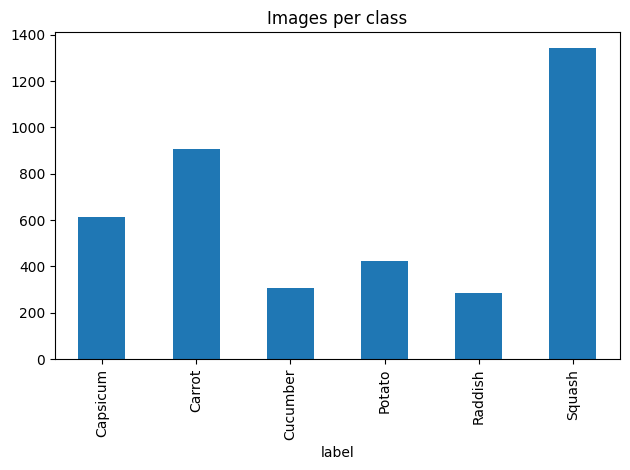


formats: {'JPEG': 3879} | modes: {'RGB': 3879}

most common sizes per class:
  Capsicum  {'200x200': 573, '4624x2084': 23, '3456x3456': 19}
  Carrot    {'200x200': 880, '4624x2084': 25}
  Cucumber  {'200x200': 293, '4624x2084': 15}
  Potato    {'200x200': 376, '3456x3456': 41, '4624x2084': 5}
  Raddish   {'200x200': 260, '4624x2084': 26}
  Squash    {'200x200': 1312, '3456x3456': 17, '4624x2084': 14}


width                                                     height  \
           count   mean     std    min    25%    50%    75%     max   count   
label                                                                         
Capsicum   615.0  466.0   995.0  200.0  200.0  200.0  200.0  4624.0   615.0   
Carrot     905.0  322.0   725.0  200.0  200.0  200.0  200.0  4624.0   905.0   
Cucumber   308.0  415.0   954.0  200.0  200.0  200.0  200.0  4624.0   308.0   
Potato     422.0  569.0  1062.0  200.0  200.0  200.0  200.0  4624.0   422.0   
Raddish    286.0  602.0  1274.0  200.0  200.0  200.0  200.0  4624.0   286.0   
Squash    1343.0  287.0   575.0  200.0  200.0  200.0  200.0  4624.0  1343.0   

                 ...                  bytes                                \
           mean  ...    75%     max   count      mean        std      min   
label            ...                                                        
Capsicum  371.0  ...  200.0  3456.0   615.0  278508.0  1082813.0  10560.0   
Carrot    252.0  ...  200.0  2084.0   905.0  117868.0   660318.0   9242.0   
Cucumber  292.0  ...  200.0  2084.0   308.0  301131.0  1369102.0  14677.0   
Potato    539.0  ...  200.0  3456.0   422.0  404777.0  1185986.0  11872.0   
Raddish   371.0  ...  200.0  2084.0   286.0  224282.0   669438.0   9192.0   
Squash    261.0  ...  200.0  3456.0  1343.0  100658.0   615872.0   8000.0   

                                                
              25%      50%      75%        max  
label                                           
Capsicum  14236.0  16599.0  19214.0  8079264.0  
Carrot    17445.0  19443.0  23162.0  7394539.0  
Cucumber  19219.0  23414.0  25882.0  8944122.0  
Potato    15701.0  18080.0  21814.0  7609110.0  
Raddish   12963.0  13654.0  14747.0  2560330.0  
Squash    13860.0  15797.0  17498.0  8271820.0  

[6 rows x 24 columns]


file-name patterns per class:
  Capsicum  {'#_#_frame_#': 573, '#_#': 42}
  Carrot    {'#_#_frame_#': 880, '#_#': 25}
  Cucumber  {'#_#_frame_#': 293, '#_#': 15}
  Potato    {'#_#_frame_#': 376, '#_#': 46}
  Raddish   {'#_#_frame_#': 260, '#_#': 26}
  Squash    {'#_#_frame_#': 1312, '#_#': 31}


In [7]:
counts = df.label.value_counts().reindex(CLASSES)
print(counts.to_string()); print('max/min ratio:', round(counts.max() / counts.min(), 2))
counts.plot.bar(title='Images per class'); plt.tight_layout(); plt.savefig(FIG / 'class_counts.png', dpi=120); plt.show()

print('\nformats:', df.format.value_counts().to_dict(), '| modes:', df['mode'].value_counts().to_dict())
df['size'] = df.width.astype(str) + 'x' + df.height.astype(str)
print('\nmost common sizes per class:')
for c in CLASSES:
    print(f'  {c:9s}', df[df.label == c]['size'].value_counts().head(4).to_dict())
display(df.groupby('label')[['width', 'height', 'bytes']].describe().round(0))

# File names: replace digits with '#', look at the most common patterns
df['pattern'] = df.name.map(lambda n: re.sub(r'\d+', '#', Path(n).stem))
print('\nfile-name patterns per class:')
for c in CLASSES:
    print(f'  {c:9s}', df[df.label == c].pattern.value_counts().head(6).to_dict())

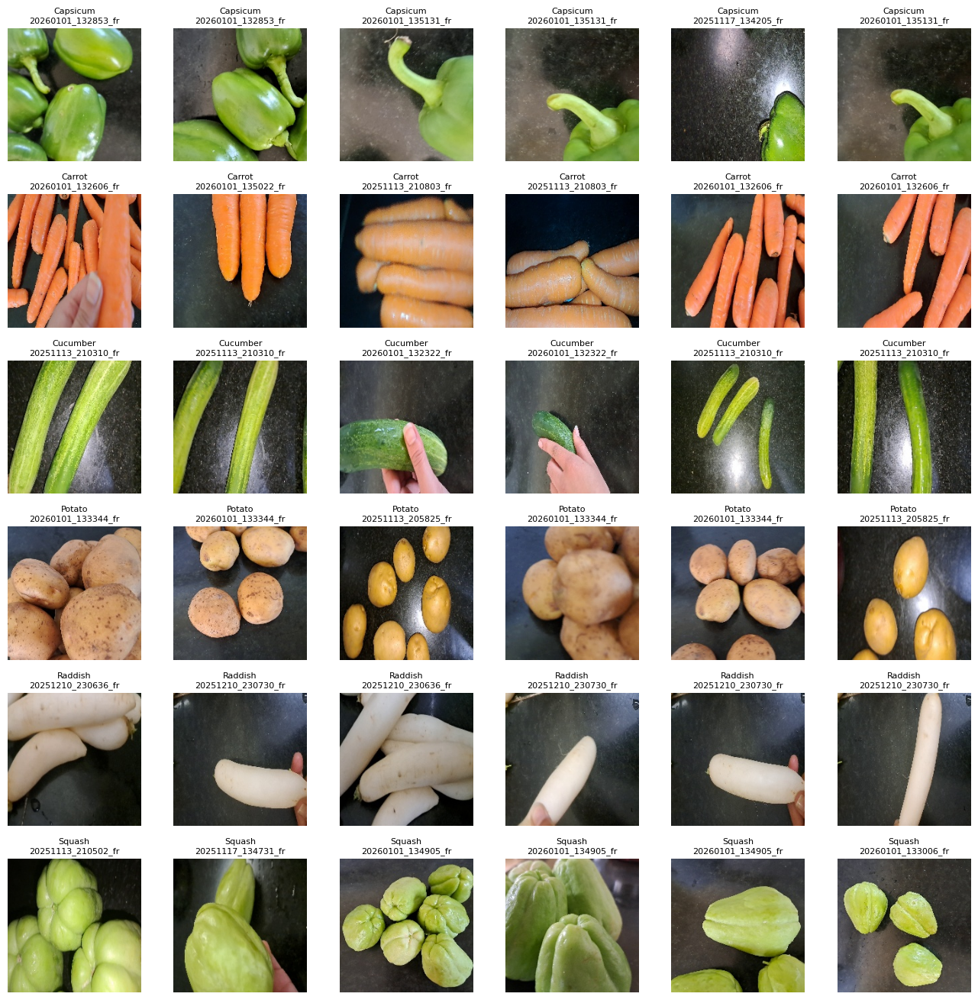

In [8]:
def show_grid(paths, titles=None, ncols=6, size=2.2, save=None):
    n = len(paths); nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    for ax in np.ravel(axes): ax.axis('off')
    for i, p in enumerate(paths):
        ax = np.ravel(axes)[i]; ax.imshow(load_rgb(p))
        if titles is not None: ax.set_title(titles[i], fontsize=8)
    plt.tight_layout()
    if save: plt.savefig(FIG / save, dpi=110)
    plt.show()

sample = df.groupby('label').sample(6, random_state=SEED)
show_grid(sample.path.tolist(), (sample.label + '\n' + sample.name.str[:18]).tolist(), save='samples.png')

### 1.3 Эмбеддинги замороженной ResNet18

**Эмбеддинг** — это 512 чисел, которыми предобученная сеть «описывает» фото.
Похожие фото → похожие векторы. Они нужны дважды: искать почти-дубликаты (обрезка, поворот —
то, что pHash пропускает) и как признаки для Трека B.

Фото **не обрезаем по центру**, а вписываем целиком в квадрат с полями (`pad_square`):
у широких фото 4624×2084 центральный кроп отрезал бы ~60% ширины, и овощ мог бы не попасть в кадр.

In [9]:
backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
backbone.fc = torch.nn.Identity()          # drop the ImageNet head -> 512-d embedding
backbone = backbone.eval().to(DEVICE)
TF = transforms.Compose([
    pad_square,                       # no CenterCrop: it would cut ~60% of a wide 4624x2084 photo
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class ImgDS(Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return TF(load_rgb(self.paths[i]))

@torch.inference_mode()
def embed(paths, bs=64):
    dl = DataLoader(ImgDS(paths), batch_size=bs, num_workers=2)
    return np.concatenate([backbone(x.to(DEVICE)).float().cpu().numpy() for x in tqdm(dl)])

X_emb = embed(df.path)
print('embeddings:', X_emb.shape)

  0%|          | 0/61 [00:00<?, ?it/s]

embeddings: (3879, 512)


### 1.4 Дубликаты и почти-дубликаты

Три проверки:
1. **точные копии** — одинаковый md5;
2. **почти-копии по pHash** — расстояние Хэмминга ≤ `HAM_THR`;
3. **почти-копии по эмбеддингам** — косинусное сходство ≥ `COS_THR` (ловит кропы/повороты).

Пороги не «из головы»: смотрим гистограмму и **глазами проверяем пары** на границе.

exact copies (md5): files involved = 0 | unique contents = 0
identical file under DIFFERENT classes: 0


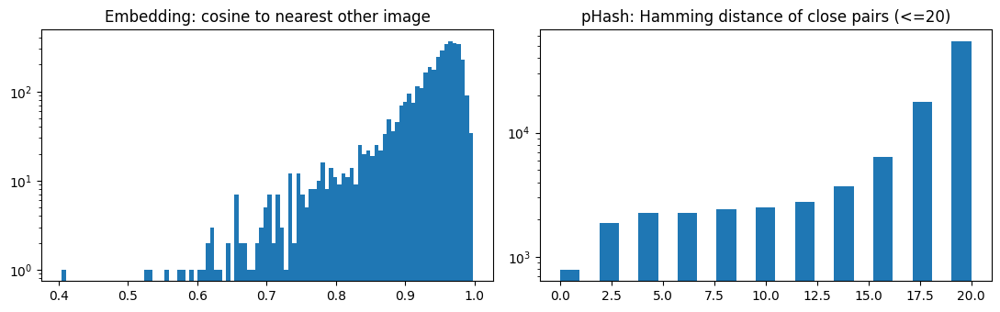

In [10]:
def hash_bits(hashes):
    return np.array([[int(b) for b in bin(int(h, 16))[2:].zfill(64)] for h in hashes], dtype=np.float32)

def close_pairs_hamming(A, B=None, thr=6, chunk=1000):
    # Pairs (i, j, distance) with Hamming distance <= thr. If B is None: pairs inside A, i < j.
    same = B is None
    B = A if same else B
    out = []
    for s in range(0, len(A), chunk):
        a = A[s:s + chunk]
        d = a @ (1 - B).T + (1 - a) @ B.T          # number of differing bits
        i, j = np.nonzero(d <= thr)
        dist = d[i, j]; i = i + s
        if same:
            keep = j > i; i, j, dist = i[keep], j[keep], dist[keep]
        out.append(np.stack([i, j, dist], 1))
    return np.concatenate(out) if out else np.empty((0, 3))

def cosine_scan(E, thr=0.95, chunk=1000):
    # Returns pairs (i, j, sim) with sim >= thr (i < j) and nearest-neighbour similarity per image
    E = E - E.mean(0)                                   # centre: ReLU features are all positive
    E = E / np.linalg.norm(E, axis=1, keepdims=True)
    out, nn = [], np.empty(len(E), dtype=np.float32)
    for s in range(0, len(E), chunk):
        S = E[s:s + chunk] @ E.T
        S[np.arange(len(S)), np.arange(s, s + len(S))] = -1     # ignore self-similarity
        nn[s:s + len(S)] = S.max(1)
        i, j = np.nonzero(S >= thr)
        sim = S[i, j]; i = i + s
        keep = j > i
        out.append(np.stack([i[keep], j[keep], sim[keep]], 1))
    return np.concatenate(out), nn

# 1) exact copies
dup_md5 = df[df.md5.duplicated(keep=False)]
print('exact copies (md5): files involved =', len(dup_md5), '| unique contents =', dup_md5.md5.nunique())
conflict = dup_md5.groupby('md5').label.nunique()
print('identical file under DIFFERENT classes:', (conflict > 1).sum())

# 2) and 3) distributions to choose thresholds
H = hash_bits(df.phash)
_, nn_sim = cosine_scan(X_emb, thr=1.01)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(nn_sim, bins=100); ax[0].set_title('Embedding: cosine to nearest other image'); ax[0].set_yscale('log')
pairs_any = close_pairs_hamming(H, thr=20)
ax[1].hist(pairs_any[:, 2], bins=21); ax[1].set_title('pHash: Hamming distance of close pairs (<=20)'); ax[1].set_yscale('log')
plt.tight_layout(); plt.savefig(FIG / 'dup_distributions.png', dpi=120); plt.show()

cosine in [0.99, 1.01)


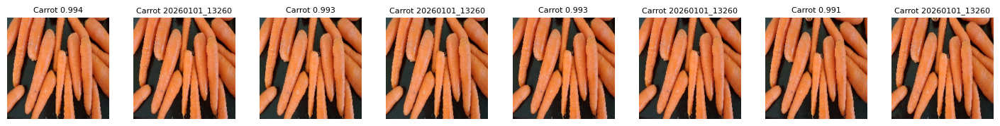

cosine in [0.97, 0.99)


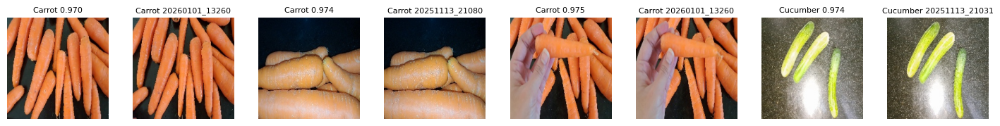

cosine in [0.95, 0.97)


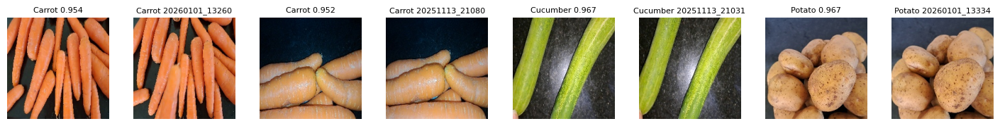

cosine in [0.92, 0.95)


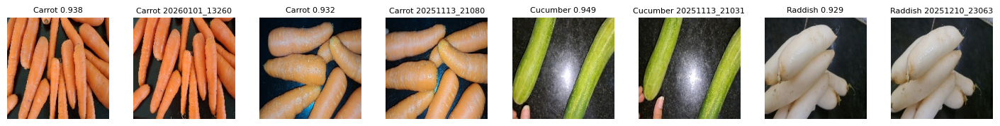

cosine in [0.9, 0.92)


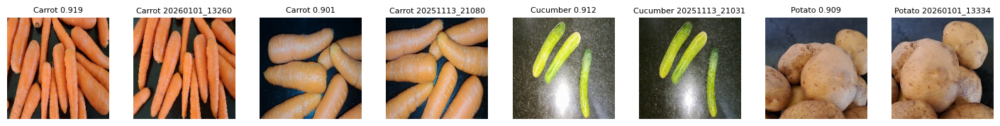

pHash distance 0-3


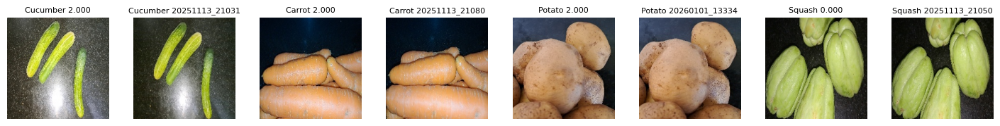

pHash distance 4-6


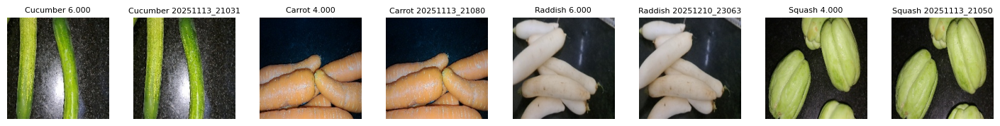

pHash distance 7-10


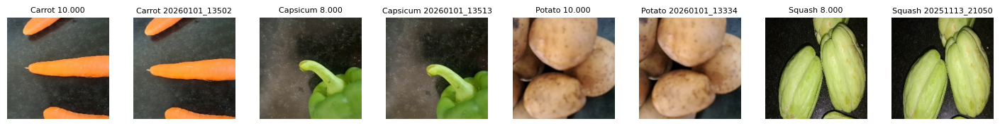

pHash distance 11-14


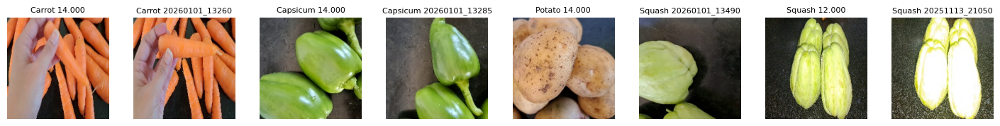

In [11]:
# Look at pairs at different similarity levels and decide where "same photo" ends
def show_pairs(pairs, n=4, title=''):
    if len(pairs) == 0: print(title, '-> no pairs'); return
    pick = pairs[np.random.default_rng(SEED).choice(len(pairs), min(n, len(pairs)), replace=False)]
    paths, titles = [], []
    for i, j, v in pick:
        i, j = int(i), int(j)
        paths += [df.path[i], df.path[j]]
        titles += [f'{df.label[i]} {v:.3f}', f'{df.label[j]} {df.name[j][:14]}']
    print(title); show_grid(paths, titles, ncols=8, size=1.8)

cos_all, _ = cosine_scan(X_emb, thr=0.90)
for lo, hi in [(0.99, 1.01), (0.97, 0.99), (0.95, 0.97), (0.92, 0.95), (0.90, 0.92)]:
    show_pairs(cos_all[(cos_all[:, 2] >= lo) & (cos_all[:, 2] < hi)], title=f'cosine in [{lo}, {hi})')
for lo, hi in [(0, 3), (4, 6), (7, 10), (11, 14)]:
    show_pairs(pairs_any[(pairs_any[:, 2] >= lo) & (pairs_any[:, 2] <= hi)], title=f'pHash distance {lo}-{hi}')

**Выберите пороги по картинкам выше.** Правило: берём порог, при котором пары ещё
явно «то же фото» (тот же овощ, тот же кадр — просто сдвиг/кроп/яркость).
Лучше чуть перестраховаться: лишнее объединение делает оценку только строже.

In [12]:
HAM_THR = 6      # <- adjust after looking at the pairs
COS_THR = 0.95   # <- adjust after looking at the pairs

ham_pairs = close_pairs_hamming(H, thr=HAM_THR)
cos_pairs = cos_all[cos_all[:, 2] >= COS_THR]
md5_pairs = np.array([(i, j) for idx in df.groupby('md5').indices.values() if len(idx) > 1
                      for i, j in zip(idx[:-1], idx[1:])]).reshape(-1, 2)

edges = np.concatenate([md5_pairs, ham_pairs[:, :2], cos_pairs[:, :2]]).astype(int)
n = len(df)
G = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])), shape=(n, n))
n_groups, df['group'] = connected_components(G, directed=False)

gsize = df.group.value_counts()
print(f'pairs: md5={len(md5_pairs)}, pHash={len(ham_pairs)}, cosine={len(cos_pairs)}')
print(f'{n} images -> {n_groups} groups of near-duplicates ({n_groups / n:.1%} "unique" photos)')
print('group size distribution:', gsize.value_counts().sort_index().head(15).to_dict())
print('largest groups:', gsize.head(5).to_dict())
mixed = df.groupby('group').label.nunique()
print('groups that mix classes (label noise?):', (mixed > 1).sum())
uniq_per_class = df.groupby('label').group.nunique().reindex(CLASSES)
display(pd.DataFrame({'images': counts, 'unique_groups': uniq_per_class,
                      'images_per_group': (counts / uniq_per_class).round(2)}))
RESULTS['dedup'] = {'HAM_THR': HAM_THR, 'COS_THR': COS_THR, 'images': int(n), 'groups': int(n_groups),
                    'largest_group': int(gsize.iloc[0]), 'mixed_label_groups': int((mixed > 1).sum())}

pairs: md5=0, pHash=7219, cosine=6079
3879 images -> 1500 groups of near-duplicates (38.7% "unique" photos)
group size distribution: {1: 1143, 2: 129, 3: 46, 4: 37, 5: 25, 6: 13, 7: 10, 8: 10, 9: 8, 10: 12, 11: 7, 12: 6, 13: 3, 14: 8, 15: 1}
largest groups: {375: 183, 324: 99, 646: 63, 912: 57, 568: 56}
groups that mix classes (label noise?): 0


,images,unique_groups,images_per_group
label,,,
Capsicum,615,318,1.93
Carrot,905,248,3.65
Cucumber,308,73,4.22
Potato,422,123,3.43
Raddish,286,125,2.29
Squash,1343,613,2.19


⚠️ Если одна группа огромная (сотни фото) — порог слишком мягкий, «склеились» просто похожие фото
на одинаковом фоне. Поднимите `COS_THR` и перезапустите ячейку.

Посмотрим на самые большие группы — это обычно и есть «размноженные» фото.

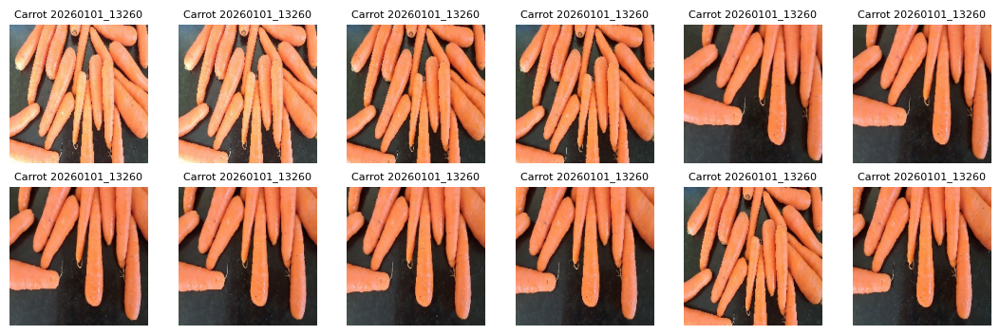

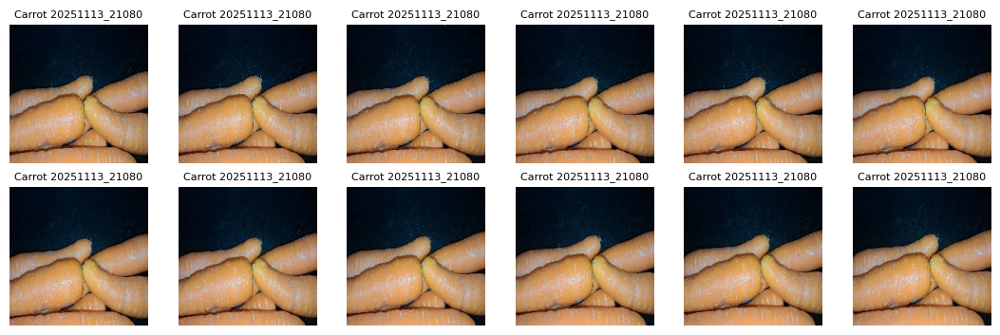

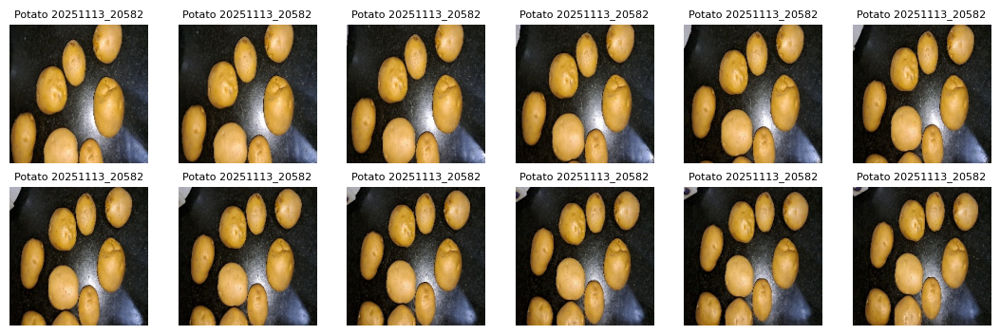

In [13]:
for g in gsize.index[:3]:
    members = df[df.group == g]
    show_grid(members.path.tolist()[:12], (members.label + ' ' + members.name.str[:14]).tolist()[:12], size=1.8)

### 1.4b Главная находка: это кадры из видео

Имена файлов `ДАТА_ВРЕМЯ_frame_N.jpg` (например `20260101_132606_frame_12.jpg`) — это **кадры одного видео**.
Соседние кадры почти одинаковые, а далёкие кадры одного видео отличаются сильнее порога похожести —
но это всё равно та же сцена: тот же овощ, стол, свет, руки. Поэтому **настоящая независимая единица — видео**,
а не отдельный кадр. Группа = все кадры одного видео + все их почти-дубликаты.

In [14]:
# Source video id from the file name: DATE_TIME_frame_N.jpg -> DATE_TIME
df['video'] = df.name.str.extract(r'^(\d{8}_\d{6})', expand=False).fillna(df.name)
df['is_frame'] = df.name.str.contains('_frame_')
df['day'] = df.name.str[:8]
print('video frames:', df.is_frame.sum(), '| single photos:', (~df.is_frame).sum())
print('videos per class:', df[df.is_frame].groupby('label').video.nunique().reindex(CLASSES).to_dict())
print('frames per video (median):', df[df.is_frame].groupby('video').size().median())
print('recording days per class:')
for c in CLASSES: print(f'  {c:9s}', sorted(df[df.label == c].day.unique()))

def chain_pairs(col):
    # connect all images that share the same value of `col`
    return np.array([(i, j) for idx in df.groupby(col).indices.values() if len(idx) > 1
                     for i, j in zip(idx[:-1], idx[1:])]).reshape(-1, 2)

E2 = np.concatenate([chain_pairs('video'), chain_pairs('group')]).astype(int)
_, df['video_group'] = connected_components(coo_matrix((np.ones(len(E2)), (E2[:, 0], E2[:, 1])), shape=(n, n)), directed=False)
gpc = df.groupby('label').video_group.nunique().reindex(CLASSES)
print('independent groups (video + near-duplicates) per class:', gpc.to_dict())
N_SPLITS = int(max(2, min(5, gpc.min())))
print('N_SPLITS =', N_SPLITS, '(each fold needs at least one group of every class)')
RESULTS['videos'] = {'frames': int(df.is_frame.sum()), 'photos': int((~df.is_frame).sum()),
                     'videos_per_class': {k: int(v) for k, v in df[df.is_frame].groupby('label').video.nunique().items()},
                     'groups_per_class': {k: int(v) for k, v in gpc.items()}, 'n_splits': N_SPLITS}

video frames: 3694 | single photos: 185
videos per class: {'Capsicum': 3, 'Carrot': 6, 'Cucumber': 2, 'Potato': 2, 'Raddish': 2, 'Squash': 4}
frames per video (median): 183.0
recording days per class:
  Capsicum  ['20251113', '20251117', '20260101']
  Carrot    ['20251113', '20260101']
  Cucumber  ['20251113', '20251117', '20260101']
  Potato    ['20251113', '20260101']
  Raddish   ['20251210']
  Squash    ['20251113', '20251117', '20260101']
independent groups (video + near-duplicates) per class: {'Capsicum': 45, 'Carrot': 31, 'Cucumber': 17, 'Potato': 48, 'Raddish': 28, 'Squash': 35}
N_SPLITS = 5 (each fold needs at least one group of every class)


### 1.5 Можно ли доверять готовому разбиению `final_dataset/` train/test?

Проверяем, есть ли в test фото, которые (почти) совпадают с фото в train. Если да — это **утечка**:
модель на тесте «узнаёт» картинки, а не распознаёт овощи.

In [15]:
def light(path):
    try:
        raw = Path(path).read_bytes()
        return hashlib.md5(raw).hexdigest(), str(imagehash.phash(load_rgb(io.BytesIO(raw))))
    except Exception:
        return None, None

for d in (tr_df, te_df):
    r = Parallel(n_jobs=-1, batch_size=32)(delayed(light)(p) for p in tqdm(d.path))
    d['md5'], d['phash'] = zip(*r)
tr_ok, te_ok = tr_df.dropna().reset_index(drop=True), te_df.dropna().reset_index(drop=True)

exact = te_ok.md5.isin(set(tr_ok.md5))
near = close_pairs_hamming(hash_bits(te_ok.phash), hash_bits(tr_ok.phash), thr=HAM_THR)
near_idx = np.unique(near[:, 0]).astype(int)
print(f'test images: {len(te_ok)}')
print(f'  exact copy of a train image (md5): {exact.sum()} ({exact.mean():.1%})')
print(f'  near-copy of a train image (pHash <= {HAM_THR}): {len(near_idx)} ({len(near_idx) / len(te_ok):.1%})')

# If final_dataset files are byte copies of Dataset/, reuse our groups (also catches crops via embeddings)
g_of = dict(zip(df.md5, df.group))
tr_g, te_g = tr_ok.md5.map(g_of), te_ok.md5.map(g_of)
print(f'  final_dataset files found in Dataset/: train {tr_g.notna().mean():.0%}, test {te_g.notna().mean():.0%}')
leak_g = te_g.isin(set(tr_g.dropna()))
print(f'  test image whose near-duplicate GROUP is in train: {leak_g.sum()} ({leak_g.mean():.1%})')
RESULTS['author_split_leak'] = {'test': len(te_ok), 'exact': int(exact.sum()), 'near_phash': int(len(near_idx)),
                                'group_leak': int(leak_g.sum())}

  0%|          | 0/3779 [00:00<?, ?it/s]

  0%|          | 0/799 [00:00<?, ?it/s]

test images: 799
  exact copy of a train image (md5): 717 (89.7%)
  near-copy of a train image (pHash <= 6): 760 (95.1%)
  final_dataset files found in Dataset/: train 100%, test 100%
  test image whose near-duplicate GROUP is in train: 769 (96.2%)


### 1.6 Наше разбиение

Используем **разбиение по видео** (`StratifiedGroupKFold`, группа = видео + почти-дубликаты):
все кадры одного видео попадают только в одну часть — либо train, либо test.
Так мы проверяем то, что нужно магазину: работает ли модель на **новой сцене**, которую не видела. «Stratified» — пропорции классов одинаковые в частях.

**Для отчёта (п. 4: что помешает в магазине)** — посмотрите на сетку примеров выше и опишите своими словами:
фон (однотонный/студийный vs полка с ценниками), один овощ в кадре vs много, освещение, упаковка/плёнка,
ракурс и масштаб, класс «овоща нет» отсутствует вообще, EXIF-поворот у фото с телефона.

# Трек B. Классические модели поверх признаков

## B.1 + B.2. Два вида признаков × два вида валидации

1. **Случайное** (`StratifiedKFold`): соседние кадры одного видео — и в train, и в test.
2. **По почти-дубликатам**: копии вместе, но разные куски одного видео могут разойтись.
3. **По видео**: всё видео целиком в одной части — самая честная оценка.

Разница между 1 и 3 ≈ насколько «случайная» оценка завышена из-за утечки.
Модель — `LogisticRegression` с `StandardScaler`, `class_weight='balanced'` (учёт дисбаланса, п. B.3).

In [16]:
y = df.label.map({c: i for i, c in enumerate(CLASSES)}).values
groups = df.video_group.values          # main split: by video
L6 = list(range(len(CLASSES)))

def make_model(C=1.0, balanced=True):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=C, max_iter=3000, class_weight='balanced' if balanced else None))

def run_cv(X, splitter, g):
    acc, f1 = [], []
    for tr, te in splitter.split(X, y, g):
        p = make_model().fit(X[tr], y[tr]).predict(X[te])
        acc.append(accuracy_score(y[te], p)); f1.append(f1_score(y[te], p, average='macro', labels=L6, zero_division=0))
    return np.mean(acc), np.std(acc), np.mean(f1), np.std(f1)

rows = []
for fname, X in [('simple: HSV hist + HOG', X_simple), ('ResNet18 embeddings', X_emb)]:
    for sname, spl, g in [('1 random', StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED), None),
                          ('2 near-duplicate groups', StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED), df.group.values),
                          ('3 video groups', StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED), df.video_group.values)]:
        a, a_sd, f, f_sd = run_cv(X, spl, g)
        rows.append({'features': fname, 'validation': sname, 'accuracy': f'{a:.3f} ± {a_sd:.3f}',
                     'macro_F1': f'{f:.3f} ± {f_sd:.3f}', '_f1': f})
        print(rows[-1])
res = pd.DataFrame(rows)
display(res.drop(columns='_f1'))
RESULTS['cv'] = res.drop(columns='_f1').to_dict('records')

{'features': 'simple: HSV hist + HOG', 'validation': '1 random', 'accuracy': '0.982 ± 0.005', 'macro_F1': '0.979 ± 0.008', '_f1': np.float64(0.9793133530016356)}
{'features': 'simple: HSV hist + HOG', 'validation': '2 near-duplicate groups', 'accuracy': '0.923 ± 0.027', 'macro_F1': '0.911 ± 0.028', '_f1': np.float64(0.9106631354588106)}
{'features': 'simple: HSV hist + HOG', 'validation': '3 video groups', 'accuracy': '0.514 ± 0.150', 'macro_F1': '0.336 ± 0.071', '_f1': np.float64(0.33626402568002844)}
{'features': 'ResNet18 embeddings', 'validation': '1 random', 'accuracy': '0.999 ± 0.001', 'macro_F1': '0.999 ± 0.001', '_f1': np.float64(0.99921079747723)}
{'features': 'ResNet18 embeddings', 'validation': '2 near-duplicate groups', 'accuracy': '0.994 ± 0.011', 'macro_F1': '0.992 ± 0.015', '_f1': np.float64(0.9920030311612565)}
{'features': 'ResNet18 embeddings', 'validation': '3 video groups', 'accuracy': '0.939 ± 0.036', 'macro_F1': '0.841 ± 0.085', '_f1': np.float64(0.840812968434711

,features,validation,accuracy,macro_F1
0,simple: HSV hist + HOG,1 random,0.982 ± 0.005,0.979 ± 0.008
1,simple: HSV hist + HOG,2 near-duplicate groups,0.923 ± 0.027,0.911 ± 0.028
2,simple: HSV hist + HOG,3 video groups,0.514 ± 0.150,0.336 ± 0.071
3,ResNet18 embeddings,1 random,0.999 ± 0.001,0.999 ± 0.001
4,ResNet18 embeddings,2 near-duplicate groups,0.994 ± 0.011,0.992 ± 0.015
5,ResNet18 embeddings,3 video groups,0.939 ± 0.036,0.841 ± 0.085


## Подробные метрики по ВСЕМ фолдам (out-of-fold)

**Out-of-fold предсказания** — каждое фото предсказывает модель, которая это фото (и его видео) **не видела**:
делим данные на 5 фолдов по видео, 5 раз учим на 4 фолдах и предсказываем пятый.
В итоге у каждого из 3879 фото есть «честное» предсказание, и матрица ошибок строится по всем видео сразу,
а не по одному фолду, где огурцов, картошки и редиса могло оказаться 8–14 штук.

Таблица ниже показывает, что попало в тест каждого фолда: `v` — целые видео, `p` — одиночные фото.

,fold,test images,Capsicum,Carrot,Cucumber,Potato,Raddish,Squash
0,0,1319,1v + 8p,3v + 5p,0v + 8p,0v + 14p,0v + 9p,2v + 9p
1,1,698,1v + 10p,0v + 9p,1v + 3p,0v + 11p,0v + 5p,1v + 5p
2,2,632,0v + 14p,0v + 6p,1v + 1p,1v + 13p,1v + 9p,1v + 9p
3,3,664,0v + 6p,2v + 2p,0v + 2p,1v + 3p,1v + 2p,0v + 5p
4,4,566,1v + 4p,1v + 3p,0v + 1p,0v + 5p,0v + 1p,0v + 3p


macro-F1 per fold: [0.832 0.843 0.796 0.994 0.738]
              precision    recall  f1-score   support

    Capsicum      0.820     0.938     0.875       615
      Carrot      0.963     0.979     0.971       905
    Cucumber      0.816     0.692     0.749       308
      Potato      0.990     0.983     0.987       422
     Raddish      0.969     0.979     0.974       286
      Squash      0.989     0.947     0.968      1343

    accuracy                          0.939      3879
   macro avg      0.925     0.920     0.921      3879
weighted avg      0.941     0.939     0.939      3879



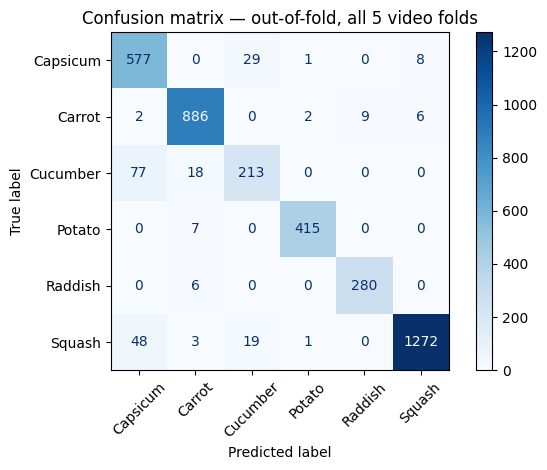

class imbalance: macro-F1 balanced 0.9205 | not balanced 0.9252

Videos (and photos) with accuracy < 90%:


images  accuracy most_common_pred
label    video                                             
Capsicum 20251113_211024       1     0.000           Squash
Cucumber 20251113_210310     168     0.667         Cucumber
         20260101_132322     125     0.688         Cucumber
Squash   20251117_134731     183     0.754           Squash
Capsicum 20251117_134205     164     0.848         Capsicum

single photos accuracy: 0.995 | video frames accuracy: 0.936


In [17]:
folds = list(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED).split(X_emb, y, groups))
P_oof, P_oof_nb, P_oof_cal = (np.zeros((len(y), len(CLASSES))) for _ in range(3))
fold_rows = []
for k, (tr, te) in enumerate(folds):
    assert not set(groups[tr]) & set(groups[te]), 'group leak!'
    m = make_model().fit(X_emb[tr], y[tr]); assert len(m.classes_) == len(CLASSES)
    P_oof[te] = m.predict_proba(X_emb[te])
    P_oof_nb[te] = make_model(balanced=False).fit(X_emb[tr], y[tr]).predict_proba(X_emb[te])
    # calibration: inner folds inside train, also by video
    n_inner = int(max(2, min(5, df.iloc[tr].groupby('label').video_group.nunique().min())))
    inner = list(StratifiedGroupKFold(n_inner, shuffle=True, random_state=SEED).split(X_emb[tr], y[tr], groups[tr]))
    P_oof_cal[te] = CalibratedClassifierCV(make_model(), method='sigmoid', cv=inner).fit(X_emb[tr], y[tr]).predict_proba(X_emb[te])
    t = df.iloc[te]
    fold_rows.append({'fold': k, 'test images': len(te), **{
        c: f"{t[(t.label == c) & t.is_frame].video.nunique()}v + {((t.label == c) & ~t.is_frame).sum()}p" for c in CLASSES}})
display(pd.DataFrame(fold_rows))

pred_oof = P_oof.argmax(1)
per_fold = [f1_score(y[te], pred_oof[te], average='macro', labels=L6, zero_division=0) for _, te in folds]
print('macro-F1 per fold:', np.round(per_fold, 3))
print(classification_report(y, pred_oof, labels=L6, target_names=CLASSES, digits=3, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y, pred_oof, labels=L6), display_labels=CLASSES).plot(xticks_rotation=45, cmap='Blues')
plt.title('Confusion matrix — out-of-fold, all 5 video folds'); plt.tight_layout()
plt.savefig(FIG / 'confusion_matrix.png', dpi=120); plt.show()

f1_b = f1_score(y, pred_oof, average='macro', labels=L6, zero_division=0)
f1_nb = f1_score(y, P_oof_nb.argmax(1), average='macro', labels=L6, zero_division=0)
print(f'class imbalance: macro-F1 balanced {f1_b:.4f} | not balanced {f1_nb:.4f}')

# Accuracy per video: are errors spread out or concentrated in a few videos?
per_video = (df.assign(correct=pred_oof == y, pred=[CLASSES[i] for i in pred_oof])
               .groupby(['label', 'video']).agg(images=('correct', 'size'), accuracy=('correct', 'mean'),
                                                most_common_pred=('pred', lambda s: s.mode()[0])))
print('\nVideos (and photos) with accuracy < 90%:')
display(per_video[per_video.accuracy < 0.9].sort_values('accuracy').round(3))
print('single photos accuracy:', round((pred_oof == y)[~df.is_frame.values].mean(), 3),
      '| video frames accuracy:', round((pred_oof == y)[df.is_frame.values].mean(), 3))

RESULTS['oof'] = {'accuracy': accuracy_score(y, pred_oof), 'macro_f1': f1_b, 'macro_f1_not_balanced': f1_nb,
                  'macro_f1_per_fold': [float(x) for x in per_fold],
                  'fold_test_composition': fold_rows,
                  'report': classification_report(y, pred_oof, labels=L6, target_names=CLASSES,
                                                  output_dict=True, zero_division=0),
                  'videos_below_90': per_video[per_video.accuracy < 0.9].reset_index().round(3).to_dict('records')}

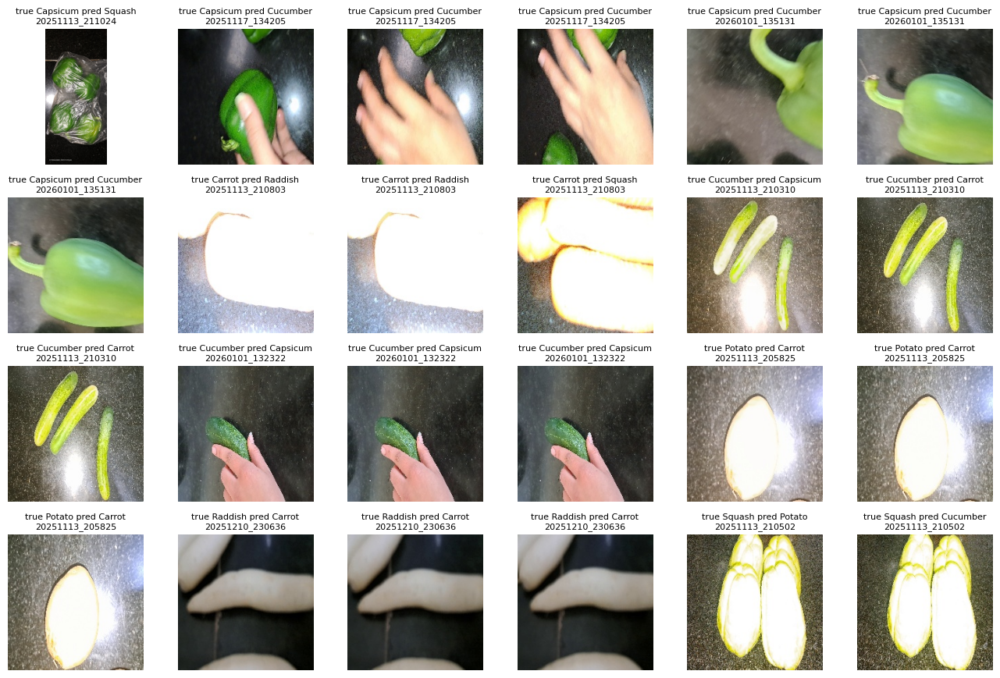

In [18]:
# Errors: up to 3 examples from each video/photo where the model was wrong
wrong = np.where(pred_oof != y)[0]
w = df.iloc[wrong].assign(i=wrong).groupby('video').head(3).i.values[:24]
if len(w):
    show_grid(df.path[w].tolist(), [f'true {CLASSES[y[i]]} pred {CLASSES[pred_oof[i]]}\n{df.video[i]}' for i in w],
              save='errors.png')

**Посмотрите на ошибки глазами** и запишите своими словами: что общего у фото, где модель ошиблась
(свет, ракурс, крупный план, фон, рука в кадре)? Это спросят на собеседовании.

## B.3. Калибровка вероятностей

**Калибровка** — насколько можно верить `confidence`. Если модель говорит «90%» на 100 фото,
то правильно должно быть ~90 из них. **Reliability diagram**: по оси X — уверенность модели,
по оси Y — реальная доля правильных ответов. Идеально — диагональ.
**ECE** (expected calibration error) — среднее расстояние до диагонали (меньше = лучше).

Сравниваем «сырую» логистическую регрессию и `CalibratedClassifierCV(method='sigmoid')` — оба на out-of-fold предсказаниях.

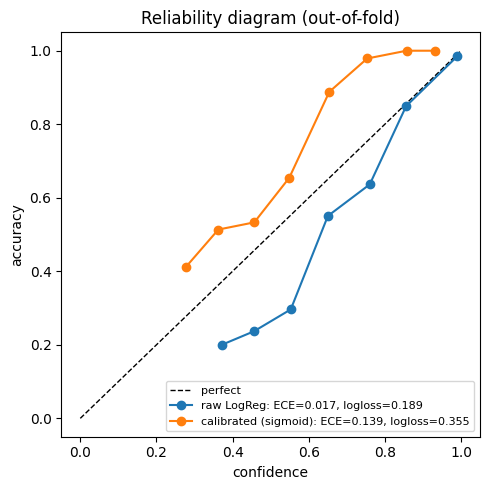

ECE: {'raw LogReg': np.float64(0.0168), 'calibrated (sigmoid)': np.float64(0.1389)} -> use calibration: False


In [19]:
def reliability(P, y_true, n_bins=10):
    conf, correct = P.max(1), P.argmax(1) == y_true
    ids = np.clip((conf * n_bins).astype(int), 0, n_bins - 1)
    xs, ys, ece = [], [], 0.0
    for b in range(n_bins):
        m = ids == b
        if m.any():
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
            ece += m.mean() * abs(conf[m].mean() - correct[m].mean())
    return np.array(xs), np.array(ys), ece

plt.figure(figsize=(5, 5)); plt.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect')
ece = {}
for name, P in [('raw LogReg', P_oof), ('calibrated (sigmoid)', P_oof_cal)]:
    xs, ys, e = reliability(P, y); ece[name] = e
    plt.plot(xs, ys, 'o-', label=f'{name}: ECE={e:.3f}, logloss={log_loss(y, P, labels=L6):.3f}')
plt.xlabel('confidence'); plt.ylabel('accuracy'); plt.legend(fontsize=8); plt.title('Reliability diagram (out-of-fold)')
plt.tight_layout(); plt.savefig(FIG / 'reliability.png', dpi=120); plt.show()

USE_CAL = ece['calibrated (sigmoid)'] < ece['raw LogReg']
print('ECE:', {k: round(v, 4) for k, v in ece.items()}, '-> use calibration:', USE_CAL)
RESULTS['calibration'] = {**{k: float(v) for k, v in ece.items()}, 'use_calibration': bool(USE_CAL)}

## B.4. Кривая обучения: сколько фото на класс нужно?

- Берём **по одному фото из группы почти-дубликатов** (только «уникальные» кадры).
- Максимальный размер = размер **самого маленького класса** в train (у Cucumber мало уникальных фото),
  чтобы при любом n все классы были **одинакового размера** — иначе кривая смешивает эффект размера и дисбаланса.
- Считаем на **всех 5 фолдах по видео** × 5 повторов случайного выбора → среднее и разброс.

⚠️ Честная оговорка: кадры одного видео похожи между собой, поэтому «50 уникальных кадров» ≠ «50 разных съёмок».
Этот график отвечает на вопрос «сколько кадров», но не «сколько видео» — для этого видео в датасете слишком мало (19).

smallest class in any train fold: 33 -> sizes: [3, 5, 10, 20, 30, 33]


,mean,std
n_per_class,,
3,0.6872,0.1394
5,0.7586,0.1107
10,0.8174,0.1097
20,0.8196,0.1051
30,0.8461,0.0962
33,0.8540,0.0741


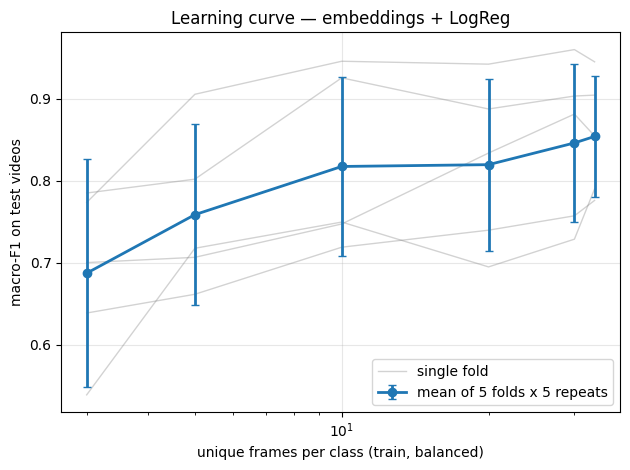

In [20]:
rng = np.random.default_rng(SEED)
fold_unique = [df.iloc[tr].drop_duplicates('group').index.values for tr, _ in folds]
max_n = min(pd.Series(y[u]).value_counts().reindex(L6, fill_value=0).min() for u in fold_unique)
sizes = sorted({s for s in [3, 5, 10, 20, 30, 40, 50, 60] if s <= max_n} | {int(max_n)})
print('smallest class in any train fold:', max_n, '-> sizes:', sizes)
lc = []
for k, ((tr, te), uniq) in enumerate(zip(folds, fold_unique)):
    for n_pc in sizes:
        for rep in range(5):
            idx = np.concatenate([rng.permutation(uniq[y[uniq] == c])[:n_pc] for c in L6])
            p = make_model().fit(X_emb[idx], y[idx]).predict(X_emb[te])
            lc.append({'fold': k, 'n_per_class': n_pc, 'rep': rep,
                       'macro_f1': f1_score(y[te], p, average='macro', labels=L6, zero_division=0)})
lc = pd.DataFrame(lc)
by_n = lc.groupby('n_per_class').macro_f1.agg(['mean', 'std'])
display(by_n.round(4))
for k in range(len(folds)):
    f = lc[lc.fold == k].groupby('n_per_class').macro_f1.mean()
    plt.plot(f.index, f.values, color='gray', alpha=.35, lw=1, label='single fold' if k == 0 else None)
plt.errorbar(by_n.index, by_n['mean'], yerr=by_n['std'], marker='o', capsize=3, lw=2, label='mean of 5 folds x 5 repeats')
plt.xscale('log'); plt.xlabel('unique frames per class (train, balanced)'); plt.ylabel('macro-F1 on test videos')
plt.title('Learning curve — embeddings + LogReg'); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(FIG / 'learning_curve.png', dpi=120); plt.show()
RESULTS['learning_curve'] = by_n.round(4).reset_index().to_dict('records')

## Бонус: ошибка «овощ есть, а его нет» в 5 раз дороже ложной тревоги

**Правильная логика.** Пусть `q` — вероятность того, что овощ **действительно есть** на фото.
Говорим «есть», если ожидаемый ущерб меньше: `5 · (1 − q) < 1 · q` → **`q > 5/6 ≈ 0.83`** (без штрафов было бы 0.5).

**Почему эту формулу нельзя честно применить к нашей модели.** Наша модель выдаёт `max p` —
уверенность **выбора одного из 6 овощей**, при условии что какой-то из них на фото есть.
Это **не** `q`: модель никогда не видела фото без овоща, и на пустой полке она тоже уверенно выберет «какой-то овощ».
Значит, `max p ≥ 0.83` ≠ «овощ есть с вероятностью ≥ 83%».

**Что нужно, чтобы формула заработала:** фото «овоща нет» (пустые полки, другие товары) → отдельная модель
или 7-й класс, выдающий `q`; откалибровать `q` и тогда ставить порог 5/6.

Ниже — только то, что можно честно проверить: если отклонять неуверенные ответы (`unknown`),
сколько фото теряем и насколько точнее становятся оставшиеся. Это порог «неуверенности», а не решение задачи «есть/нет».

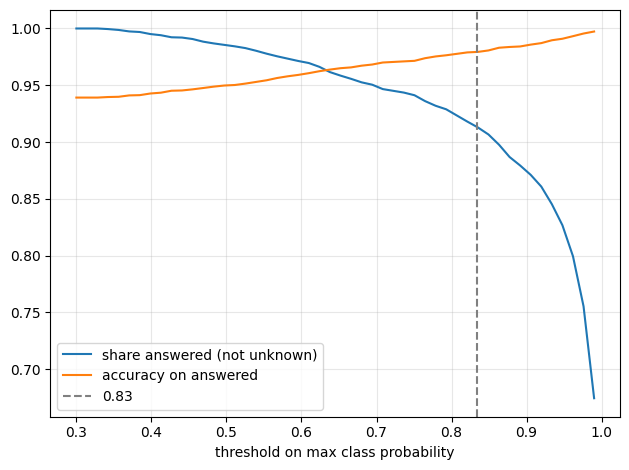

threshold 0.83 on max p: answered 91.4%, accuracy on answered 0.979


In [21]:
P = P_oof_cal if USE_CAL else P_oof
conf, ok = P.max(1), P.argmax(1) == y
ts = np.linspace(0.3, 0.99, 50)
kept = [(conf >= t).mean() for t in ts]
acc_kept = [ok[conf >= t].mean() if (conf >= t).any() else np.nan for t in ts]
plt.plot(ts, kept, label='share answered (not unknown)'); plt.plot(ts, acc_kept, label='accuracy on answered')
plt.axvline(5 / 6, ls='--', c='gray', label='0.83'); plt.xlabel('threshold on max class probability'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / 'threshold.png', dpi=120); plt.show()
t = 5 / 6
print(f'threshold {t:.2f} on max p: answered {(conf >= t).mean():.1%}, accuracy on answered {ok[conf >= t].mean():.3f}')
RESULTS['unknown_threshold_0.83'] = {'answered': float((conf >= t).mean()), 'accuracy_on_answered': float(ok[conf >= t].mean())}

# Финальная модель, predict.py, замер на CPU

Финальную модель учим на **всех** данных (метрики выше уже честно посчитаны out-of-fold по видео).
Поэтому проверка `predict.py` ниже — только «скрипт работает и быстро», а не оценка точности.

In [22]:
import sklearn, PIL, joblib
cv_all = list(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED).split(X_emb, y, groups))
final = (CalibratedClassifierCV(make_model(), method='sigmoid', cv=cv_all) if USE_CAL else make_model()).fit(X_emb, y)
joblib.dump({'model': final, 'classes': CLASSES}, REPO / 'weights' / 'classifier.joblib')
torch.save({k: v.cpu() for k, v in backbone.state_dict().items()}, REPO / 'weights' / 'backbone_resnet18.pt')

v = lambda m: m.__version__.split('+')[0]
(REPO / 'requirements.txt').write_text(
    '--extra-index-url https://download.pytorch.org/whl/cpu\n'
    f'torch=={v(torch)}\ntorchvision=={v(torchvision)}\nscikit-learn=={v(sklearn)}\n'
    f'numpy=={v(np)}\npillow=={v(PIL)}\njoblib=={v(joblib)}\n')
import scipy, skimage, matplotlib
(REPO / 'requirements-train.txt').write_text(
    '-r requirements.txt\n'
    f'pandas=={v(pd)}\nscipy=={v(scipy)}\nscikit-image=={v(skimage)}\nmatplotlib=={v(matplotlib)}\n'
    f'imagehash=={v(imagehash)}\nkagglehub\ntqdm\n')
print((REPO / 'requirements.txt').read_text())
for f in sorted((REPO / 'weights').iterdir()): print(f.name, round(f.stat().st_size / 1e6, 1), 'MB')

--extra-index-url https://download.pytorch.org/whl/cpu
torch==2.14.1
torchvision==0.29.1
scikit-learn==1.6.1
numpy==2.4.6
pillow==11.3.0
joblib==1.6.0

backbone_resnet18.pt 44.8 MB
classifier.joblib 0.0 MB


In [23]:
%%writefile /content/repo/predict.py
"""Vegetable classifier: frozen ResNet18 embeddings + (calibrated) logistic regression.

Usage:
    python predict.py --input path/to/folder --output preds.csv [--threshold 0.83]

Runs on CPU, no internet needed: all weights are loaded from ./weights.
"""
import argparse
import csv
import time
from pathlib import Path

import joblib
import numpy as np
import torch
from PIL import Image, ImageOps
from torchvision import models, transforms

HERE = Path(__file__).resolve().parent
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def pad_square(img, fill=(124, 116, 104)):
    # Fit the whole photo into a square (no cropping), same as in training
    w, h = img.size
    side = max(w, h)
    out = Image.new("RGB", (side, side), fill)
    out.paste(img, ((side - w) // 2, (side - h) // 2))
    return out


# Same preprocessing as in training (see notebook)
TF = transforms.Compose([
    pad_square,
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


def load_rgb(path, max_side=320):
    img = Image.open(path)
    img.draft("RGB", (max_side, max_side))  # fast JPEG downscale while decoding
    img = ImageOps.exif_transpose(img)      # phone photos: respect EXIF rotation
    return img.convert("RGB")


def load_backbone(weights_path):
    net = models.resnet18(weights=None)
    net.fc = torch.nn.Identity()
    net.load_state_dict(torch.load(weights_path, map_location="cpu"))
    return net.eval()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--input", required=True, help="folder with images")
    ap.add_argument("--output", required=True, help="path to preds.csv")
    ap.add_argument("--weights-dir", default=str(HERE / "weights"))
    ap.add_argument("--threshold", type=float, default=0.0,
                    help="confidence below this -> 'unknown' (0 = never unknown)")
    ap.add_argument("--batch-size", type=int, default=32)
    args = ap.parse_args()

    t_start = time.perf_counter()
    wdir = Path(args.weights_dir)
    net = load_backbone(wdir / "backbone_resnet18.pt")
    bundle = joblib.load(wdir / "classifier.joblib")
    clf, classes = bundle["model"], bundle["classes"]
    t_loaded = time.perf_counter()

    root = Path(args.input)
    files = sorted(p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in EXTS)
    rows = []

    for s in range(0, len(files), args.batch_size):
        batch = files[s:s + args.batch_size]
        tensors, names = [], []
        for p in batch:
            name = p.relative_to(root).as_posix()
            try:
                tensors.append(TF(load_rgb(p)))
                names.append(name)
            except Exception as e:  # broken file: do not crash the whole run
                print(f"WARNING: cannot read {name}: {e}")
                rows.append((name, "unknown", 0.0))
        if not tensors:
            continue
        with torch.inference_mode():
            emb = net(torch.stack(tensors)).numpy()
        probs = clf.predict_proba(emb)
        for name, pr in zip(names, probs):
            k = int(np.argmax(pr))
            conf = float(pr[k])
            label = classes[k] if conf >= args.threshold else "unknown"
            rows.append((name, label, round(conf, 4)))

    rows.sort(key=lambda r: r[0])
    with open(args.output, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["filename", "label", "confidence"])
        w.writerows(rows)

    t_end = time.perf_counter()
    n = max(len(files), 1)
    print(f"images: {len(files)} -> {args.output}")
    print(f"model load: {t_loaded - t_start:.2f} s")
    print(f"per image (read + preprocess + predict, CPU): {1000 * (t_end - t_loaded) / n:.1f} ms")


if __name__ == "__main__":
    main()

Writing /content/repo/predict.py


In [24]:
# CPU timing + "does the script work" check.
# NOTE: the final model was trained on ALL images, including these 60 -> this is NOT an accuracy estimate.
# Honest quality numbers are the out-of-fold metrics above.
sample_dir = Path('/content/sample_cpu'); shutil.rmtree(sample_dir, ignore_errors=True); sample_dir.mkdir()
pick = np.random.default_rng(SEED).choice(len(df), 60, replace=False)
for i in pick: shutil.copy(df.path[i], sample_dir / f'{i}{Path(df.path[i]).suffix}')
!CUDA_VISIBLE_DEVICES="" python /content/repo/predict.py --input /content/sample_cpu --output /content/preds_sample.csv
preds = pd.read_csv('/content/preds_sample.csv')
preds['true'] = preds.filename.map(lambda f: df.label[int(Path(f).stem)])
print('agreement with labels (seen in training, sanity only):', (preds.label == preds.true).mean()); display(preds.head())

images: 60 -> /content/preds_sample.csv
model load: 1.59 s
per image (read + preprocess + predict, CPU): 73.7 ms
agreement with labels (seen in training, sanity only): 1.0


,filename,label,confidence,true
0,1067.jpg,Carrot,0.9992,Carrot
1,1369.jpg,Carrot,0.9979,Carrot
2,1409.jpg,Carrot,1.0000,Carrot
3,1424.jpg,Carrot,0.9998,Carrot
4,1547.jpg,Cucumber,0.9999,Cucumber


In [25]:
(REPO / 'results.json').write_text(json.dumps(RESULTS, indent=2, default=float))
shutil.make_archive('/content/repo', 'zip', REPO)
from google.colab import files; files.download('/content/repo.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Не забудьте:** File → Download → .ipynb, положите ноутбук в репозиторий рядом с `predict.py`.